# Importing Libraries

In [24]:
%pip install pandas numpy matplotlib seaborn scipy statsmodels prophet arff

Note: you may need to restart the kernel to use updated packages.


In [25]:

# AIR QUALITY FORECASTING USING TIME SERIES
# IMPORT LIBRARIES

# Data Manipulation
import pandas as pd
import numpy as np

# Load ARFF Dataset
from scipy.io import arff

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Date and Time Handling
from datetime import datetime

# Statistical Time Series Models
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Stationarity Testing
from statsmodels.tsa.stattools import adfuller

# Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

# Prophet Forecasting
from prophet import Prophet

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# Suppress Warnings
import warnings
warnings.filterwarnings("ignore")


# Data Loading

In [30]:
import arff

print(arff.__file__)

c:\Users\grace\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\arff\__init__.py


In [31]:
print(arff)

<module 'arff' from 'c:\\Users\\grace\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\arff\\__init__.py'>


In [33]:
import arff

gen = arff.load("dataset.arff")

print(type(gen))

first = next(gen)

print(type(first))
print(first)

<class 'generator'>
<class 'arff.GenerateRowBase.<locals>.Row'>
<Row(1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,'N',4.4,'otizhongxi')>


In [34]:
import pandas as pd

# Find where data starts
with open("dataset.arff", "r", encoding="utf-8") as f:
    lines = f.readlines()

data_start = next(
    i for i, line in enumerate(lines)
    if "@DATA" in line.upper()
)

# Read data section only
df = pd.read_csv(
    "dataset.arff",
    skiprows=data_start + 1,
    header=None
)

df.columns = [
    "No",
    "year",
    "month",
    "day",
    "hour",
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "wd",
    "WSPM",
    "station"
]

df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


# Data  Preprocessing

Missing Values

In [ ]:
# Replace missing values represented by "?" with NaN
df.replace("?", np.nan, inplace=True)

print(df.isnull().sum())

No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64


In [ ]:
# interpolate missing values for numeric columns
df[numeric_cols] = (df[numeric_cols].interpolate())

Converting numerical features

In [36]:
numeric_cols = [
    "PM2.5","PM10","SO2","NO2",
    "CO","O3","TEMP","PRES",
    "DEWP","RAIN","WSPM"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

Converting date trime frame

In [ ]:
# convert year, month, day, hour to datetime
df["datetime"] = pd.to_datetime(
    dict(
        year=df.year,
        month=df.month,
        day=df.day,
        hour=df.hour
    )
)

df = df.sort_values("datetime")
df.set_index("datetime", inplace=True)

Outlier analysis

In [ ]:
# check for outliers in numeric columns using IQR method
numeric_cols = [
    "PM2.5","PM10","SO2","NO2",
    "CO","O3","TEMP",
    "PRES","DEWP","RAIN","WSPM"
]

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = df[
        (df[col] < lower) |
        (df[col] > upper)
    ].shape[0]

    print(f"{col}: {count} outliers")

PM2.5: 19612 outliers
PM10: 15150 outliers
SO2: 36626 outliers
NO2: 7255 outliers
CO: 29224 outliers
O3: 16662 outliers
TEMP: 0 outliers
PRES: 0 outliers
DEWP: 0 outliers
RAIN: 16527 outliers
WSPM: 23124 outliers


In [42]:
# Winsorization using IQR method 
# Numerical columns

numeric_cols = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

# Winsorization using IQR method

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap lower outliers
    df[col] = np.where(
        df[col] < lower_bound,
        lower_bound,
        df[col]
    )

    # Cap upper outliers
    df[col] = np.where(
        df[col] > upper_bound,
        upper_bound,
        df[col]
    )

print("Winsorization completed successfully.")

Winsorization completed successfully.


Creating a date time format

In [44]:
df["datetime"] = pd.to_datetime(
    dict(
        year=df["year"],
        month=df["month"],
        day=df["day"],
        hour=df["hour"]
    )
)

df = df.reset_index(drop=True).sort_values("datetime")

df.set_index("datetime", inplace=True)

# Exploratory Data Analysis

Dataset shape

In [64]:
print(df.shape)
print(df.info())
print(df.describe())

(420768, 18)
<class 'pandas.DataFrame'>
DatetimeIndex: 420768 entries, 2013-03-01 00:00:00 to 2017-02-28 23:00:00
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    420768 non-null  float64
 6   PM10     420768 non-null  float64
 7   SO2      420768 non-null  float64
 8   NO2      420768 non-null  float64
 9   CO       420768 non-null  float64
 10  O3       420768 non-null  float64
 11  TEMP     420768 non-null  float64
 12  PRES     420768 non-null  float64
 13  DEWP     420768 non-null  float64
 14  RAIN     420768 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420768 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 65.4 MB
None
        

PM2.5 Trend

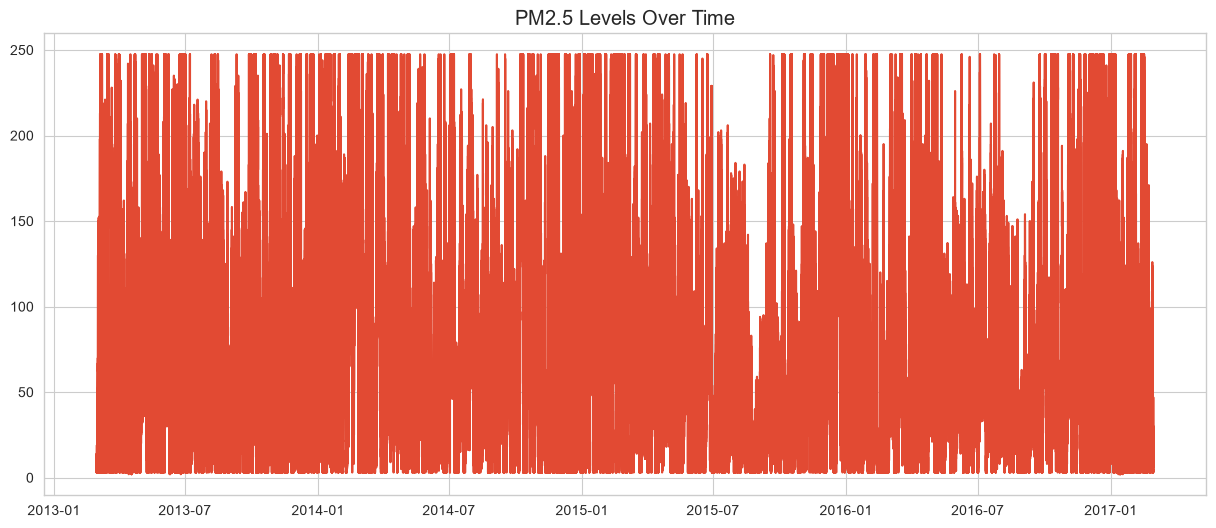

In [46]:
plt.figure(figsize=(15,6))

plt.plot(df["PM2.5"])

plt.title("PM2.5 Levels Over Time")

plt.show()

Correlation HeatMap

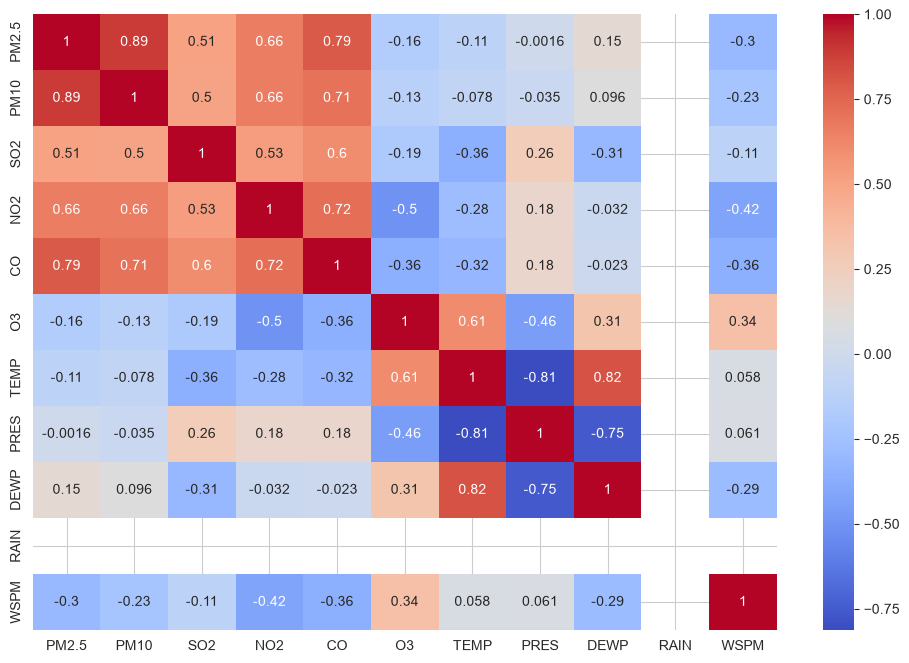

In [47]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

# Feature Engineering

Lag features

In [65]:
df["PM25_lag_1"] = (
    df["PM2.5"].shift(1)
)

df["PM25_lag_24"] = (
    df["PM2.5"].shift(24)
)

df["PM25_lag_48"] = (
    df["PM2.5"].shift(48)
)

Moving Averages

In [66]:
df["MA_24"] = (
    df["PM2.5"]
    .rolling(24)
    .mean()
)

df["MA_72"] = (
    df["PM2.5"]
    .rolling(72)
    .mean()
)

Time Features

In [67]:
df["month"] = df.index.month
df["day_of_week"] = df.index.dayofweek
df["hour"] = df.index.hour

# Daily Aggregation

In [68]:
daily_df = df.resample("D").mean(numeric_only=True)

daily_df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,...,PRES,DEWP,RAIN,WSPM,PM25_lag_1,PM25_lag_24,PM25_lag_48,MA_24,MA_72,day_of_week
datetime,,,,,,,,,,,,,,,,,,,,,
2013-03-01,12.5,2013.0,3.0,1.0,11.5,7.326389,12.203125,9.151042,20.581597,404.861111,...,1026.569792,-20.148611,0.0,2.718229,7.306620,6.893939,6.420833,7.166824,6.837046,4.0
2013-03-02,36.5,2013.0,3.0,2.0,11.5,31.475694,40.506944,28.686697,56.303763,939.715278,...,1026.552778,-16.271875,0.0,1.142882,31.305556,25.142361,20.059028,28.518808,23.066647,5.0
2013-03-03,60.5,2013.0,3.0,3.0,11.5,79.291667,111.104167,34.112847,75.605903,1744.781250,...,1014.215278,-12.325347,0.0,1.384896,79.402778,82.618056,81.166667,80.934606,81.260224,6.0
2013-03-04,84.5,2013.0,3.0,4.0,11.5,21.768569,40.359375,18.311747,40.877151,717.663194,...,1017.263194,-12.773264,0.0,2.206597,21.699124,20.905344,24.902627,21.179342,23.452613,0.0
2013-03-05,108.5,2013.0,3.0,5.0,11.5,125.198445,159.022569,41.642361,96.368924,1954.812500,...,1010.551389,-7.916319,0.0,0.992014,124.629001,112.559934,99.145984,119.090696,106.214753,1.0


# Stationary Test

In [69]:
result = adfuller(
    daily_df["PM2.5"].dropna()
)

print("ADF Statistic:", result[0])
print("P-value:", result[1])

ADF Statistic: -22.029002504383584
P-value: 0.0


# Seasonal Decomposition

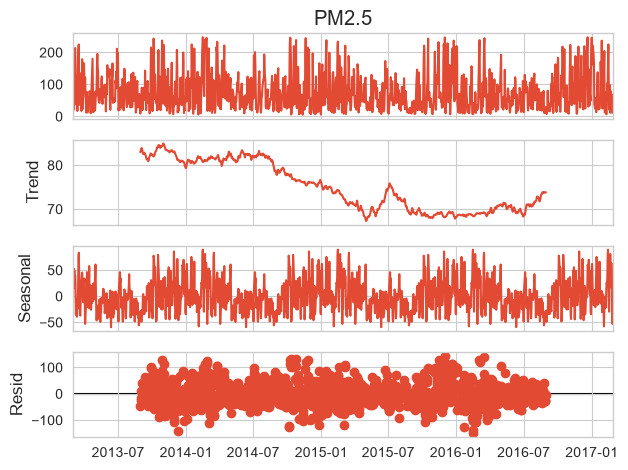

In [70]:
decomposition = seasonal_decompose(
    daily_df["PM2.5"],
    model="additive",
    period=365
)

decomposition.plot()

plt.show()

# Model

Train- Test Split

In [71]:
split = int(len(daily_df) * 0.8)

train = daily_df.iloc[:split]
test = daily_df.iloc[split:]

Model

ARIMA

In [72]:
# Fit ARIMA model
model = ARIMA(
    train["PM2.5"],
    order=(5,1,2)
)

arima_model = model.fit()

arima_pred = arima_model.forecast(
    steps=len(test)
)

In [73]:
# Evaluate ARIMA model
arima_rmse = np.sqrt(
    mean_squared_error(
        test["PM2.5"],
        arima_pred
    )
)

arima_mae = mean_absolute_error(
    test["PM2.5"],
    arima_pred
)

print(arima_rmse)
print(arima_mae)

57.234745882859585
45.40176250692022


SARIMA

In [74]:
# Fit SARIMA model
sarima = SARIMAX(
    train["PM2.5"],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

sarima_model = sarima.fit()

sarima_pred = sarima_model.forecast(
    len(test)
)

In [75]:
# Evaluate SARIMA model
sarima_rmse = np.sqrt(
    mean_squared_error(
        test["PM2.5"],
        sarima_pred
    )
)

sarima_mae = mean_absolute_error(
    test["PM2.5"],
    sarima_pred
)

print(sarima_rmse)
print(sarima_mae)

58.01766666304554
44.63429293865245


PROPHET

In [76]:
# Prepare data for Prophet model
prophet_df = daily_df.reset_index()

prophet_df = prophet_df[
    ["datetime","PM2.5"]
]

prophet_df.columns = [
    "ds",
    "y"
]

In [77]:
# Split data into training and testing sets
split = int(len(prophet_df)*0.8)

train_prophet = prophet_df[:split]
test_prophet = prophet_df[split:]

In [78]:
# Train Prophet model
prophet_model = Prophet()

prophet_model.fit(
    train_prophet
)

05:49:22 - cmdstanpy - INFO - Chain [1] start processing
05:49:23 - cmdstanpy - INFO - Chain [1] done processing


In [79]:
# Make future dataframe for predictions
future = prophet_model.make_future_dataframe(
    periods=len(test_prophet),
    freq="D"
)

forecast = prophet_model.predict(
    future
)

In [80]:
# Evaluate Prophet model
prophet_pred = forecast["yhat"].tail(
    len(test_prophet)
)

In [81]:
# Evaluate Prophet model 
prophet_rmse = np.sqrt(
    mean_squared_error(
        test_prophet["y"],
        prophet_pred
    )
)

prophet_mae = mean_absolute_error(
    test_prophet["y"],
    prophet_pred
)

print(prophet_rmse)
print(prophet_mae)

54.75843281505951
41.022563736894696


Model Comparison

In [82]:
# Create a DataFrame to summarize the results
results = pd.DataFrame({

    "Model":[
        "ARIMA",
        "SARIMA",
        "Prophet"
    ],

    "RMSE":[
        arima_rmse,
        sarima_rmse,
        prophet_rmse
    ],

    "MAE":[
        arima_mae,
        sarima_mae,
        prophet_mae
    ]
})

results

,Model,RMSE,MAE
0,ARIMA,57.234746,45.401763
1,SARIMA,58.017667,44.634293
2,Prophet,54.758433,41.022564


Model comparison visualisation

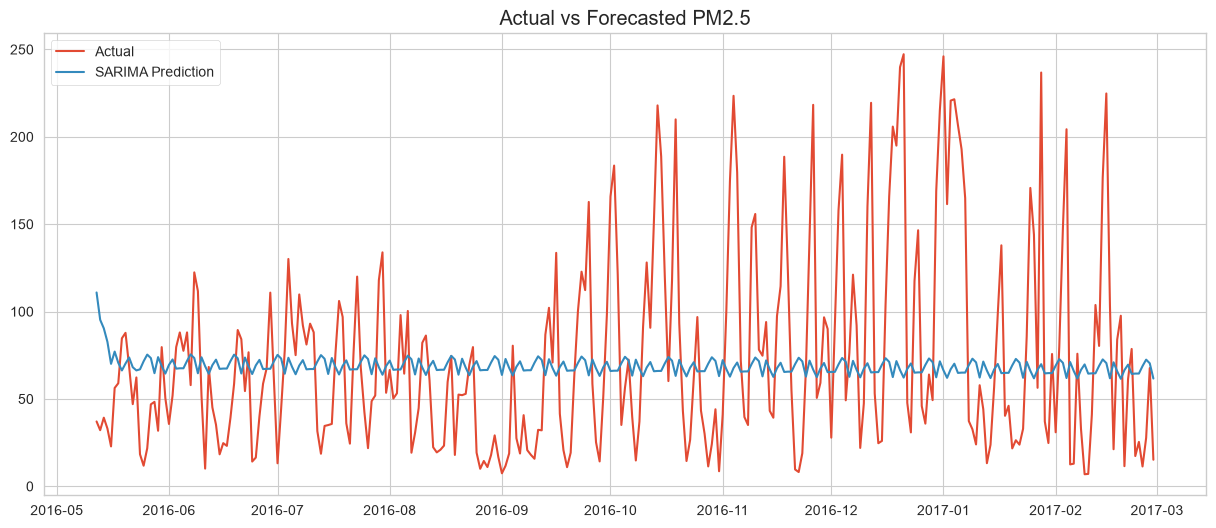

In [83]:
plt.figure(figsize=(15,6))

plt.plot(
    test.index,
    test["PM2.5"],
    label="Actual"
)

plt.plot(
    test.index,
    sarima_pred,
    label="SARIMA Prediction"
)

plt.legend()

plt.title(
    "Actual vs Forecasted PM2.5"
)

plt.show()